# Computer Vision — Section 3 Solutions

<a href="https://colab.research.google.com/github/amr-elgharip2006/cv-section3-opencv/blob/main/CV_Section3_Solutions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Student:** Amr Ahmed Elgharip

# Solutions — Amr

The cells below rebuild the section's test image and noise functions, so they run on their own (Colab: *Runtime → Run all*, no upload needed).
Task 6 uses OpenCV's sample photo `fruits.jpg`, downloaded from the OpenCV repository.

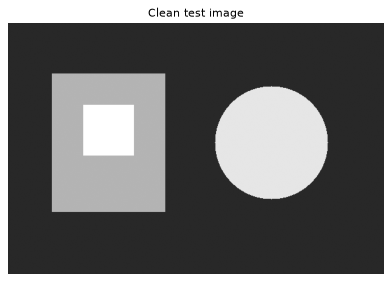

In [1]:
import os
import urllib.request

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Same clean test image as the section
img = np.full((400, 600), 40, dtype=np.uint8)
cv2.rectangle(img, (70, 80), (250, 300), 180, -1)
cv2.circle(img, (420, 190), 90, 230, -1)
cv2.rectangle(img, (120, 130), (200, 210), 255, -1)


def add_gaussian_noise(image, mean=0, sigma=25):
    noise = np.random.normal(mean, sigma, image.shape)
    noisy = image.astype(np.float32) + noise
    return np.clip(noisy, 0, 255).astype(np.uint8)


def add_salt_pepper_noise(image, amount=0.03):
    noisy = image.copy()
    n = int(amount * image.size)
    rows = np.random.randint(0, image.shape[0], n)
    cols = np.random.randint(0, image.shape[1], n)
    noisy[rows, cols] = 0
    rows = np.random.randint(0, image.shape[0], n)
    cols = np.random.randint(0, image.shape[1], n)
    noisy[rows, cols] = 255
    return noisy


def show(images, titles, cols=None, size=3.4):
    cols = cols or len(images)
    rows = int(np.ceil(len(images) / cols))
    plt.figure(figsize=(size * cols, size * 0.75 * rows), dpi=80)
    for i, (im, t) in enumerate(zip(images, titles), 1):
        plt.subplot(rows, cols, i)
        if im.ndim == 3:
            plt.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        else:
            plt.imshow(im, cmap="gray", vmin=0, vmax=255)
        plt.title(t, fontsize=10)
        plt.axis("off")
    plt.tight_layout()
    plt.show()


show([img], ["Clean test image"], size=5)

### Task 1 — Noise (Solution)

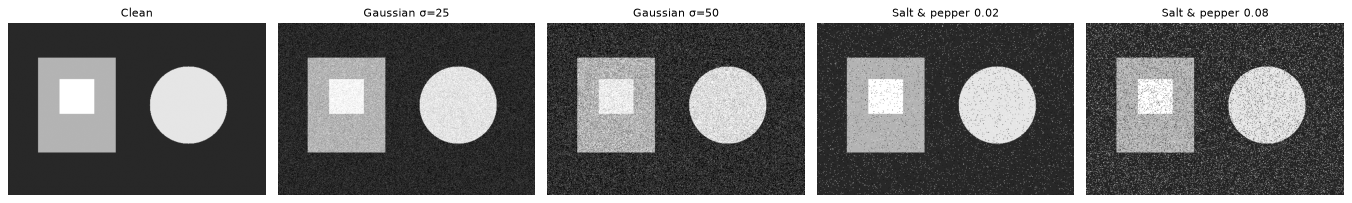

image                  PSNR (dB)   changed pixels
Gaussian sigma=25          20.67            66.5%
Gaussian sigma=50          15.69            82.2%
Salt&pepper 0.02           18.37             3.9%
Salt&pepper 0.08           12.64            14.6%


In [2]:
np.random.seed(42)
g25 = add_gaussian_noise(img, sigma=25)
g50 = add_gaussian_noise(img, sigma=50)

np.random.seed(42)
sp02 = add_salt_pepper_noise(img, amount=0.02)
sp08 = add_salt_pepper_noise(img, amount=0.08)

show([img, g25, g50, sp02, sp08],
     ["Clean", "Gaussian σ=25", "Gaussian σ=50", "Salt & pepper 0.02", "Salt & pepper 0.08"])

# PSNR: higher = closer to the clean image
print(f"{'image':<22}{'PSNR (dB)':>10}{'changed pixels':>17}")
for name, im in [("Gaussian sigma=25", g25), ("Gaussian sigma=50", g50),
                 ("Salt&pepper 0.02", sp02), ("Salt&pepper 0.08", sp08)]:
    changed = np.mean(np.abs(im.astype(int) - img) > 10) * 100
    print(f"{name:<22}{cv2.PSNR(img, im):>10.2f}{changed:>16.1f}%")

**Which image is harder to recognize?**
- Doubling the Gaussian sigma (25 → 50) drops the PSNR from 20.7 to 15.7 dB. Almost every pixel changes, so the whole image becomes grainy and the gray rectangle starts to blend into the background, but the shapes are still visible.
- Raising salt & pepper from 0.02 to 0.08 drops the PSNR from 18.4 to **12.6 dB**, the lowest of the four. About 15% of the pixels become pure black or white, so the dots cover the objects, and the small bright square is the hardest part to see.
- **Salt & pepper 0.08 is the hardest to recognize.** Gaussian σ=50 changes more pixels, but each change is smaller.

### Task 2 — Filtering (Solution)

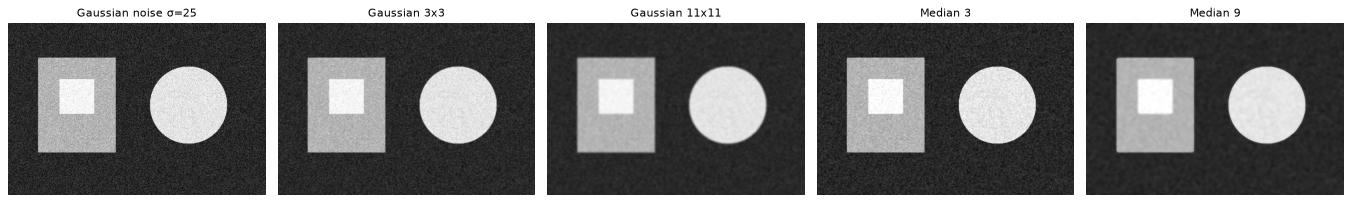

Gaussian noise σ=25 -> PSNR after filtering: Gaussian 3x3: 28.0 dB, Gaussian 11x11: 28.7 dB, Median 3: 27.8 dB, Median 9: 32.6 dB


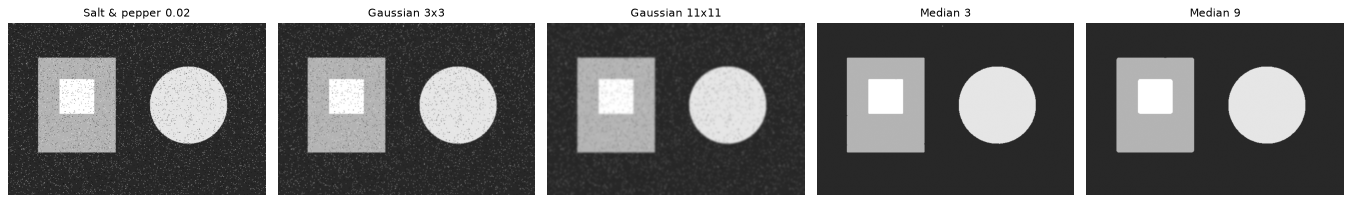

Salt & pepper 0.02 -> PSNR after filtering: Gaussian 3x3: 25.9 dB, Gaussian 11x11: 27.9 dB, Median 3: 41.3 dB, Median 9: 38.4 dB


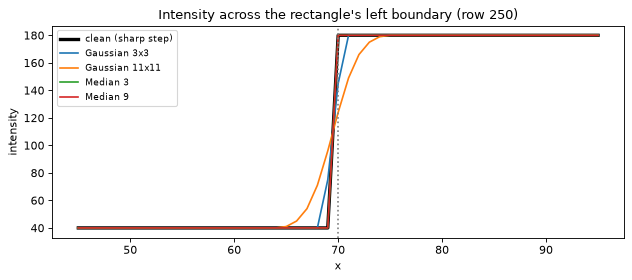

Edge width (10%-90%) on the clean image: Gaussian 3x3: 2 px, Gaussian 11x11: 4 px, Median 3: 0 px, Median 9: 0 px


In [3]:
def apply_filters(noisy):
    return {
        "Gaussian 3x3": cv2.GaussianBlur(noisy, (3, 3), 0),
        "Gaussian 11x11": cv2.GaussianBlur(noisy, (11, 11), 0),
        "Median 3": cv2.medianBlur(noisy, 3),
        "Median 9": cv2.medianBlur(noisy, 9),
    }

for noisy, label in [(g25, "Gaussian noise σ=25"), (sp02, "Salt & pepper 0.02")]:
    results = apply_filters(noisy)
    show([noisy] + list(results.values()), [label] + list(results.keys()), cols=5)
    print(label, "-> PSNR after filtering:",
          ", ".join(f"{k}: {cv2.PSNR(img, v):.1f} dB" for k, v in results.items()))

# Boundary sharpness: filter the CLEAN image and look at a row crossing the left edge of the rectangle (x = 70)
row = 250
xs = np.arange(45, 96)
plt.figure(figsize=(8, 3.6), dpi=80)
plt.plot(xs, img[row, xs], "k-", lw=3, label="clean (sharp step)")
for name, f in apply_filters(img).items():
    plt.plot(xs, f[row, xs], label=name)
plt.axvline(70, color="gray", ls=":")
plt.title(f"Intensity across the rectangle's left boundary (row {row})")
plt.xlabel("x")
plt.ylabel("intensity")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

def edge_width(profile):
    # pixels needed to go from 10% to 90% of the step (40 -> 180)
    lo, hi = 40 + 0.1 * 140, 40 + 0.9 * 140
    return int(np.sum((profile > lo) & (profile < hi)))

print("Edge width (10%-90%) on the clean image:",
      ", ".join(f"{k}: {edge_width(v[row, xs].astype(float))} px" for k, v in apply_filters(img).items()))

**Which filter preserves the object boundaries better? → Median.**
- On the clean image, the median filter keeps the edge as a perfect step (edge width **0 px**), while Gaussian 3×3 spreads it over 2 px and Gaussian 11×11 over 4 px. A Gaussian is an average, so it always mixes the two sides of an edge. The median just picks one of the existing values, so it does not create the in-between grays.
- For **salt & pepper**, the median is far better: median 3 reaches 41.3 dB, while the best Gaussian only reaches 27.9 dB. The Gaussian only spreads each dot into a gray blob.
- For **Gaussian noise**, median 9 gives the highest PSNR (32.6 dB), and Gaussian 11×11 removes the noise but makes the boundaries visibly soft.
- **Trade-off:** a big median (9) starts to round the corners of the rectangle and would remove thin details, so the kernel should be only as big as the noise needs.

### Task 3 — Thresholding (Solution)

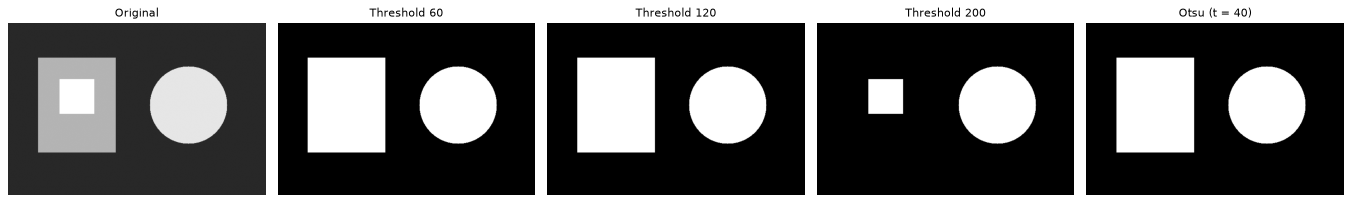

threshold  60: IoU = 1.000   objects kept: rectangle (180), circle (230), small square (255)
threshold 120: IoU = 1.000   objects kept: rectangle (180), circle (230), small square (255)
threshold 200: IoU = 0.489   objects kept: circle (230), small square (255)
Otsu  (40): IoU = 1.000   objects kept: rectangle (180), circle (230), small square (255)


In [4]:
objects = img > 40          # ground truth: everything that is not background

def iou(pred, truth):
    pred = pred > 0
    return np.sum(pred & truth) / np.sum(pred | truth)

def describe(binary):
    kept = [name for name, (x, y) in {"rectangle (180)": (90, 280), "circle (230)": (420, 260),
                                      "small square (255)": (160, 170)}.items() if binary[y, x] > 0]
    return ", ".join(kept) if kept else "nothing"

otsu_t, otsu = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
manual = {t: cv2.threshold(img, t, 255, cv2.THRESH_BINARY)[1] for t in (60, 120, 200)}

show([img] + list(manual.values()) + [otsu],
     ["Original"] + [f"Threshold {t}" for t in manual] + [f"Otsu (t = {otsu_t:.0f})"], cols=5)

for t, b in manual.items():
    print(f"threshold {t:>3}: IoU = {iou(b, objects):.3f}   objects kept: {describe(b)}")
print(f"Otsu  ({otsu_t:.0f}): IoU = {iou(otsu, objects):.3f}   objects kept: {describe(otsu)}")

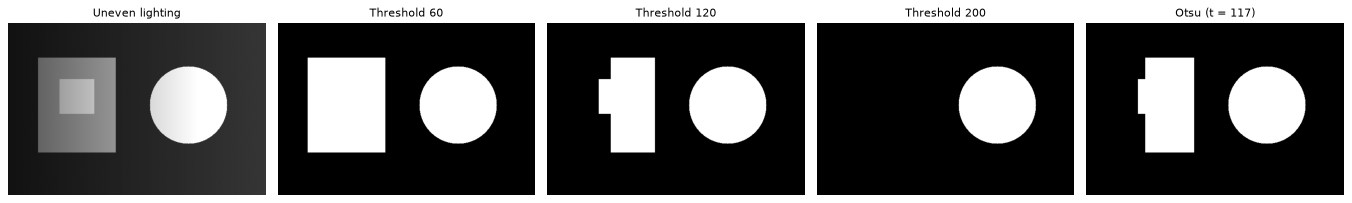

uneven, threshold  60: IoU = 1.000   objects kept: rectangle (180), circle (230), small square (255)
uneven, threshold 120: IoU = 0.771   objects kept: circle (230), small square (255)
uneven, threshold 200: IoU = 0.389   objects kept: circle (230)
uneven, Otsu  (117): IoU = 0.795   objects kept: circle (230), small square (255)


In [5]:
# When does a manual threshold fail? Same image under uneven lighting (dark on the left, bright on the right)
light = np.tile(np.linspace(0.45, 1.35, img.shape[1]), (img.shape[0], 1))
uneven = np.clip(img * light, 0, 255).astype(np.uint8)

manual_uneven = {t: cv2.threshold(uneven, t, 255, cv2.THRESH_BINARY)[1] for t in (60, 120, 200)}
ot_u, otsu_uneven = cv2.threshold(uneven, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

show([uneven] + list(manual_uneven.values()) + [otsu_uneven],
     ["Uneven lighting"] + [f"Threshold {t}" for t in manual_uneven] + [f"Otsu (t = {ot_u:.0f})"], cols=5)
for t, b in manual_uneven.items():
    print(f"uneven, threshold {t:>3}: IoU = {iou(b, objects):.3f}   objects kept: {describe(b)}")
print(f"uneven, Otsu  ({ot_u:.0f}): IoU = {iou(otsu_uneven, objects):.3f}   objects kept: {describe(otsu_uneven)}")

- On the clean image, 60 and 120 both separate all three objects (IoU = 1.0). **200 fails**: the rectangle has intensity 180, which is below the threshold, so it disappears (IoU 0.49).
- Otsu picks **t = 40** automatically and finds all three objects.
- Under **uneven lighting**, the left side is darker. Threshold 120 now loses the rectangle, 200 keeps only the circle, and even Otsu (117) loses the rectangle, because one global value cannot fit both the dark and the bright side.

**When does a manual threshold fail?**
1. When the threshold sits above the intensity of an object you need, or below the background.
2. When the lighting changes across the image, because the same object has different intensities in different places. Adaptive thresholding is the fix here.
3. When noise pushes pixels across the threshold.
4. When you reuse a value tuned for one image on another image. It has to be tuned again for every image.

### Task 4 — Morphology (Solution)

original         specks left:  50 | hole filled: False | gap closed: False | object area: 66563
opening  3x3    specks left:  51 | hole filled: False | gap closed: False | object area: 66563
closing  3x3    specks left:  48 | hole filled: False | gap closed: False | object area: 66563
opening  7x7    specks left:   0 | hole filled: False | gap closed: False | object area: 66563
closing  7x7    specks left:  44 | hole filled: False | gap closed: False | object area: 66563
opening 11x11   specks left:   0 | hole filled: False | gap closed: False | object area: 66563
closing 11x11   specks left:  42 | hole filled: False | gap closed: True  | object area: 68372
closing 15x15   specks left:  41 | hole filled: True  | gap closed: True  | object area: 68541  <- extra, not asked


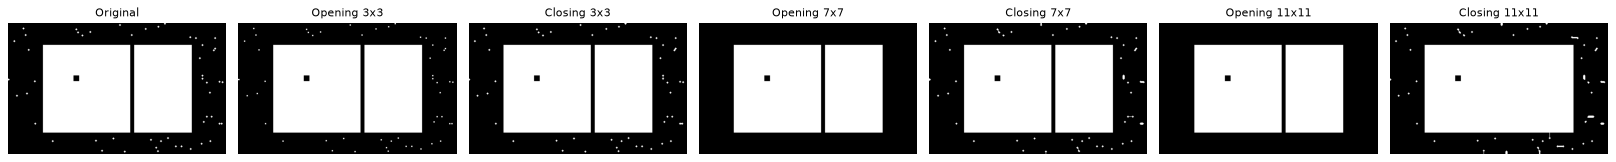

In [6]:
# Same mask as the section: white rectangle + background specks + a 13x13 hole + a 9 px wide gap
mask = np.zeros((300, 500), dtype=np.uint8)
cv2.rectangle(mask, (80, 50), (420, 250), 255, -1)
np.random.seed(42)
for _ in range(120):
    x, y = np.random.randint(0, 500), np.random.randint(0, 300)
    if x < 70 or x > 430 or y < 40 or y > 260:
        cv2.circle(mask, (x, y), 2, 255, -1)
cv2.rectangle(mask, (150, 120), (162, 132), 0, -1)   # hole
cv2.rectangle(mask, (280, 50), (288, 250), 0, -1)    # gap

def report(m):
    outside = m.copy()
    outside[45:256, 75:426] = 0                        # ignore the big object, count only specks
    specks = cv2.connectedComponents(outside)[0] - 1
    return (f"specks left: {specks:>3} | hole filled: {m[126, 156] == 255!s:<5} | "
            f"gap closed: {m[150, 284] == 255!s:<5} | object area: {np.count_nonzero(m[50:251, 80:421])}")

images, titles = [mask], ["Original"]
print(f"{'original':<16}", report(mask))
for k in (3, 7, 11):
    kernel = np.ones((k, k), np.uint8)
    opened = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
    closed = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
    images += [opened, closed]
    titles += [f"Opening {k}x{k}", f"Closing {k}x{k}"]
    print(f"opening {k:>2}x{k:<2}  ", report(opened))
    print(f"closing {k:>2}x{k:<2}  ", report(closed))

# extra: the hole is 13x13, so it needs a kernel bigger than that
closed15 = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, np.ones((15, 15), np.uint8))
print(f"closing 15x15  ", report(closed15), " <- extra, not asked")

show(images, titles, cols=7, size=2.9)

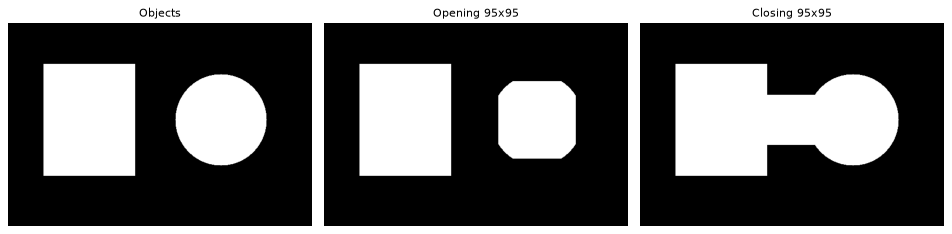

objects: 2 | after opening 95x95: 2 | after closing 95x95: 1
circle area kept by opening: 86%


In [7]:
# Kernel too large: binary version of the test image (rectangle + circle, 80 px apart)
shapes = cv2.threshold(img, 100, 255, cv2.THRESH_BINARY)[1]
big = np.ones((95, 95), np.uint8)
open_big = cv2.morphologyEx(shapes, cv2.MORPH_OPEN, big)
close_big = cv2.morphologyEx(shapes, cv2.MORPH_CLOSE, big)

n_objects = lambda m: cv2.connectedComponents(m)[0] - 1
show([shapes, open_big, close_big],
     ["Objects", "Opening 95x95", "Closing 95x95"], size=4)
print("objects:", n_objects(shapes), "| after opening 95x95:", n_objects(open_big),
      "| after closing 95x95:", n_objects(close_big))
print(f"circle area kept by opening: {np.count_nonzero(open_big[:, 330:]) / np.count_nonzero(shapes[:, 330:]):.0%}")

| Kernel | Opening | Closing |
|---|---|---|
| 3×3 | Does nothing useful. The specks (5 px dots) are bigger than the kernel, so they survive. | Does not fill the 13 px hole or the 9 px gap. |
| 7×7 | **Removes all the specks** and keeps the rectangle unchanged. | Still too small for the hole and the gap. |
| 11×11 | Removes all the specks. | **Closes the 9 px gap**, but the 13 px hole stays (it needs about 15×15). |

Rule: **opening removes white things smaller than the kernel; closing fills black holes and gaps smaller than the kernel.**

**What happens when the kernel becomes too large?** It starts to damage the real objects:
- **Opening** with 95×95 cuts the round parts of the circle (only 86% of its area is left) and would delete any object thinner than the kernel.
- **Closing** with 95×95 joins the rectangle and the circle into **one object** (2 → 1), because the 80 px gap between them is smaller than the kernel.

So the kernel should be just bigger than the noise or gap you want to fix, and smaller than the objects and the spaces between them.

### Task 5 — Canny (Solution)

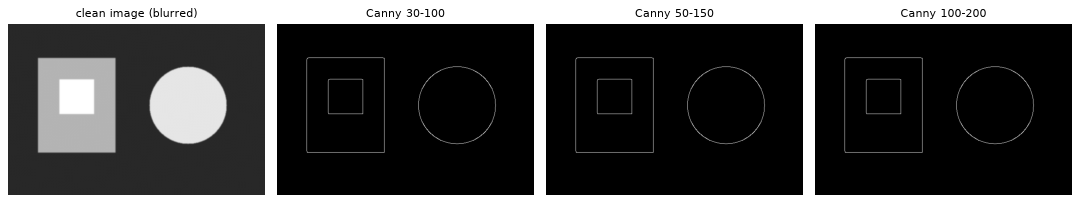

clean image (blurred)        Canny  30-100: edge pixels =   1744, unwanted =      0
clean image (blurred)        Canny  50-150: edge pixels =   1744, unwanted =      0
clean image (blurred)        Canny 100-200: edge pixels =   1744, unwanted =      0


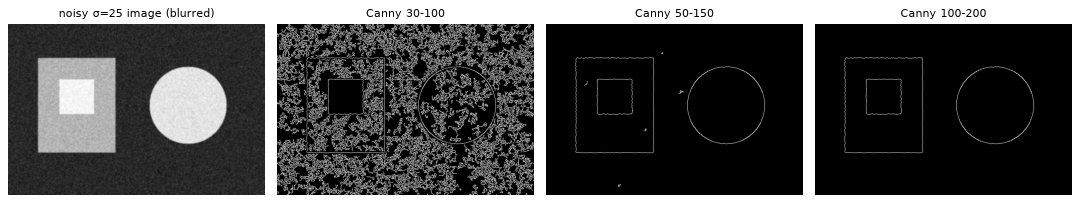

noisy σ=25 image (blurred)   Canny  30-100: edge pixels =  53784, unwanted =  51969
noisy σ=25 image (blurred)   Canny  50-150: edge pixels =   1871, unwanted =     85
noisy σ=25 image (blurred)   Canny 100-200: edge pixels =   1786, unwanted =      0


In [8]:
# True boundaries of the clean image (allow 2 px tolerance)
true_edges = cv2.dilate(cv2.Canny(img, 50, 150), np.ones((5, 5), np.uint8))

settings = [(30, 100), (50, 150), (100, 200)]
clean_blur = cv2.GaussianBlur(img, (5, 5), 0)
noisy_blur = cv2.GaussianBlur(g25, (5, 5), 0)

for source, label in [(clean_blur, "clean image (blurred)"), (noisy_blur, "noisy σ=25 image (blurred)")]:
    edges = [cv2.Canny(source, lo, hi) for lo, hi in settings]
    show([source] + edges, [label] + [f"Canny {lo}-{hi}" for lo, hi in settings], cols=4)
    for (lo, hi), e in zip(settings, edges):
        total = np.count_nonzero(e)
        unwanted = np.count_nonzero((e > 0) & (true_edges == 0))
        print(f"{label:<28} Canny {lo:>3}-{hi:<3}: edge pixels = {total:>6}, unwanted = {unwanted:>6}")

- **On the clean image**, all three settings give the same 1,744 edge pixels, because every edge is a strong step that passes even the high threshold.
- **On the noisy image**, the difference is huge:
  - **(30, 100)** detects the most edges (53,784 pixels), but **51,969 of them are unwanted** noise edges.
  - **(50, 150)** gives 1,871 edge pixels, of which only 85 are wrong.
  - **(100, 200)** gives 1,786 edge pixels with **no** wrong edges.

**Answer:** low thresholds detect more edges but also produce the most unwanted edges. High thresholds keep only strong edges, which is cleaner but can miss weak, real edges in real photos. Blurring first and choosing a ratio of about 1:2 or 1:3 between the two thresholds is the usual balance.

### Task 6 — My own pipeline (Solution)

**Read → Grayscale → Noise → Filter → Threshold → Morphology → Canny** on OpenCV's `fruits.jpg`.

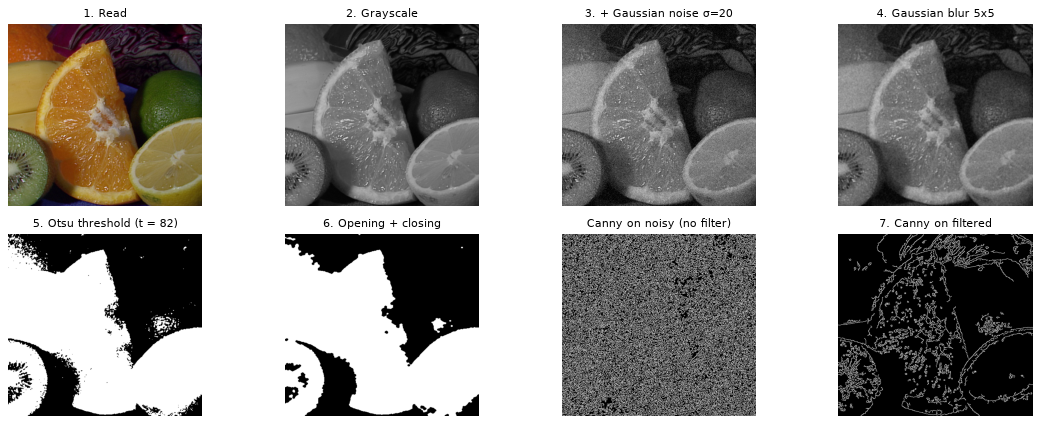

edge pixels without filtering: 88538
edge pixels after filtering:   19254
white regions before / after morphology: 163 / 9


In [9]:
# 1. Read: a real photo (downloaded once from the OpenCV samples)
PHOTO = "fruits.jpg"
if not os.path.exists(PHOTO):
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/opencv/opencv/4.x/samples/data/fruits.jpg", PHOTO)
photo = cv2.imread(PHOTO)

# 2. Grayscale: thresholding, morphology and Canny all work on one intensity channel
gray = cv2.cvtColor(photo, cv2.COLOR_BGR2GRAY)

# 3. Noise: simulate a low-light camera (Gaussian noise) to see how each step copes with it
np.random.seed(0)
noisy = add_gaussian_noise(gray, sigma=20)

# 4. Filter: the noise is Gaussian, so a Gaussian blur fits it; 5x5 removes most grain
#    without melting the fruit outlines (11x11 would blur them a lot, see Task 2)
smooth = cv2.GaussianBlur(noisy, (5, 5), 0)

# 5. Threshold: lighting is fairly even and the histogram has a bright group (fruit) and a
#    dark group (cabbage / shadows), so Otsu can pick the global threshold automatically
t, binary = cv2.threshold(smooth, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# 6. Morphology: opening (5x5) removes small white specks left by the threshold,
#    closing (7x7) fills small dark holes such as seeds and highlights inside the fruit
k_open = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
k_close = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
clean_mask = cv2.morphologyEx(binary, cv2.MORPH_OPEN, k_open)
clean_mask = cv2.morphologyEx(clean_mask, cv2.MORPH_CLOSE, k_close)

# 7. Canny on the smoothed image: blurring first stops the noise from creating fake edges
edges_noisy = cv2.Canny(noisy, 50, 150)
edges = cv2.Canny(smooth, 50, 150)

show([photo, gray, noisy, smooth, binary, clean_mask, edges_noisy, edges],
     ["1. Read", "2. Grayscale", "3. + Gaussian noise σ=20", "4. Gaussian blur 5x5",
      f"5. Otsu threshold (t = {t:.0f})", "6. Opening + closing", "Canny on noisy (no filter)",
      "7. Canny on filtered"], cols=4, size=3.6)

print("edge pixels without filtering:", np.count_nonzero(edges_noisy))
print("edge pixels after filtering:  ", np.count_nonzero(edges))
print("white regions before / after morphology:",
      cv2.connectedComponents(binary)[0] - 1, "/", cv2.connectedComponents(clean_mask)[0] - 1)

The reason for each step is in the comments above. The numbers show that the steps help:
- **Filtering before Canny** cut the edge pixels from 88,538 (mostly noise) to 19,254, so the fruit outlines are visible again.
- **Morphology** reduced the white regions after thresholding from 163 small pieces to 9 clean regions.

### Final Challenge — Document Cleanup (Solution)

A synthetic "photographed document" is used so the result can be checked against the real text: it has **uneven lighting** (a shadow on the left), **noise**, **dark text** and **small gaps in the letters**.

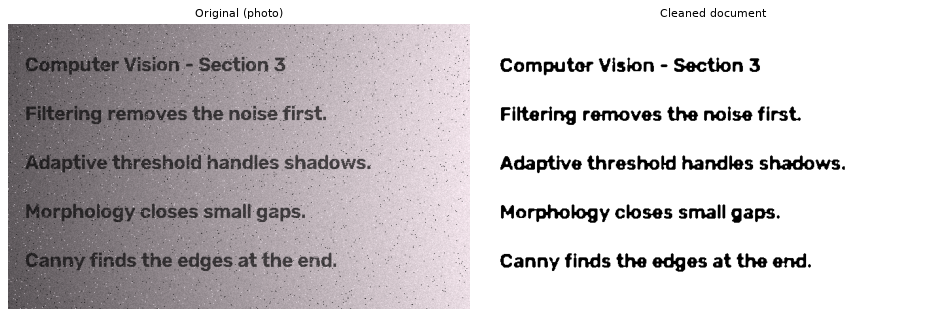

In [10]:
def make_document(seed=3):
    rng = np.random.default_rng(seed)
    h, w = 420, 680
    text = np.zeros((h, w), np.uint8)
    lines = ["Computer Vision - Section 3",
             "Filtering removes the noise first.",
             "Adaptive threshold handles shadows.",
             "Morphology closes small gaps.",
             "Canny finds the edges at the end."]
    for i, line in enumerate(lines):
        cv2.putText(text, line, (25, 70 + i * 72), cv2.FONT_HERSHEY_SIMPLEX, 1.0, 255, 2, cv2.LINE_AA)
    truth = text > 127                       # the real text, used only to score the results

    broken = truth.copy()                    # small gaps in the letters
    for _ in range(260):
        y, x = rng.integers(0, h), rng.integers(0, w - 6)
        broken[y, x:x + 6] = False

    # paper brightness: dark shadow on the left, brighter on the right, slight vignette
    yy, xx = np.mgrid[0:h, 0:w]
    paper = 95 + 140 * (xx / w) - 25 * ((yy - h / 2) / h) ** 2
    page = paper * np.where(broken, 0.35, 1.0)
    page = page + rng.normal(0, 9, page.shape)                       # sensor noise
    page = np.clip(page, 0, 255).astype(np.uint8)
    specks = rng.random(page.shape)
    page[specks < 0.006] = 0
    page[specks > 0.994] = 255                                        # salt & pepper dust
    color = cv2.merge([page, np.clip(page * 0.97, 0, 255).astype(np.uint8),
                       np.clip(page * 1.03, 0, 255).astype(np.uint8)])  # slightly warm "photo"
    return color, truth

document_image, truth = make_document()

# Step 0: grayscale
gray_doc = cv2.cvtColor(document_image, cv2.COLOR_BGR2GRAY)

# Step 1: filtering - median 3 removes the salt & pepper dust and keeps the letter edges sharp
filtered = cv2.medianBlur(gray_doc, 3)

# Step 2: adaptive threshold - each pixel is compared with its own 31x31 neighbourhood,
# so the dark shadow on the left does not matter. INV makes the text white (foreground).
text_mask = cv2.adaptiveThreshold(filtered, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                  cv2.THRESH_BINARY_INV, 31, 15)

# Step 3: morphology - opening removes leftover specks, closing fills the small gaps in the letters
text_mask = cv2.morphologyEx(text_mask, cv2.MORPH_OPEN, np.ones((2, 2), np.uint8))
text_mask = cv2.morphologyEx(text_mask, cv2.MORPH_CLOSE, np.ones((3, 3), np.uint8))
clean_doc = cv2.bitwise_not(text_mask)       # back to black text on white paper

show([document_image, clean_doc], ["Original (photo)", "Cleaned document"], size=6)

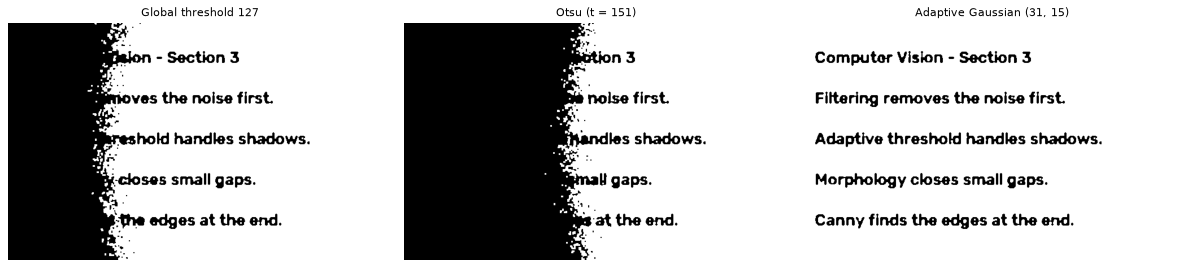

method                     F1   text found   paper marked as text
Global 127              0.308        87.1%                 26.86%
Otsu (151)              0.230        93.0%                 43.69%
Adaptive                0.761        77.0%                  1.81%


In [11]:
# Extension: global vs Otsu vs adaptive (same filtering and morphology for all three)
def finish(text_white):
    m = cv2.morphologyEx(text_white, cv2.MORPH_OPEN, np.ones((2, 2), np.uint8))
    return cv2.morphologyEx(m, cv2.MORPH_CLOSE, np.ones((3, 3), np.uint8))

global_t = finish(cv2.threshold(filtered, 127, 255, cv2.THRESH_BINARY_INV)[1])
otsu_value, otsu_raw = cv2.threshold(filtered, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
otsu_t = finish(otsu_raw)
adaptive_t = text_mask

def score(pred_white):
    pred = pred_white > 0
    tp = np.sum(pred & truth)
    precision = tp / max(np.sum(pred), 1)
    recall = tp / np.sum(truth)
    f1 = 2 * precision * recall / max(precision + recall, 1e-9)
    wrong_paper = np.mean(pred[~truth]) * 100
    return f1, recall, wrong_paper

show([cv2.bitwise_not(global_t), cv2.bitwise_not(otsu_t), cv2.bitwise_not(adaptive_t)],
     ["Global threshold 127", f"Otsu (t = {otsu_value:.0f})", "Adaptive Gaussian (31, 15)"], cols=3, size=5)

print(f"{'method':<22}{'F1':>7}{'text found':>13}{'paper marked as text':>23}")
for name, m in [("Global 127", global_t), (f"Otsu ({otsu_value:.0f})", otsu_t), ("Adaptive", adaptive_t)]:
    f1, rec, wrong = score(m)
    print(f"{name:<22}{f1:>7.3f}{rec * 100:>12.1f}%{wrong:>22.2f}%")

**Which method works best, and why? → Adaptive.**
- **Global 127** and **Otsu (151)** use one value for the whole page. The paper on the shadowed left side is darker than the threshold, so it is classified as text and the whole left part turns black: about 27% and 44% of the paper is wrong, and the F1 score is only 0.31 and 0.23.
- **Adaptive (Gaussian, 31×31 block, C = 15)** compares each pixel with its own neighbourhood. A letter is always darker than the paper right around it, even inside the shadow, so the text comes out on both sides and only **1.8%** of the paper is wrong, with **F1 = 0.76**.
- Before the threshold, the **median 3** filter removes the dust. After it, **opening** removes the leftover dots and **closing** fills the small gaps inside the letters.

Otsu is not "wrong": it is the best global value for this histogram. But no single global value can work when the lighting changes across the page.